# Vibration of cylinders with integral blade stringers: Sewall and Naumann (1968)

J. L. Sewall and E. C. Naumann, *An experimental and analytical vibration study of thin cylindrical shells with and without longitudinal stiffeners*, NASA TN D-4705, September 1968 (NTRS 19680024266).
D. M. Egle and J. L. Sewall, *An analysis of free vibration of orthogonally stiffened cylindrical shells with stiffeners treated as discrete elements*, AIAA Journal 6(3) (1968) 518-526, https://doi.org/10.2514/3.4528.

Three aluminium cylinders of the same radius and skin thickness were vibration-tested at NASA Langley: an unstiffened shell (U), and two shells machined with 60 integral rectangular (blade) stringers, inside (IS, internally stiffened) or outside (ES, externally stiffened) the skin. Each was tested free-free (FF), simply supported (SS), clamped-free (CF) and clamped-clamped (CC), and the resonant frequencies are tabulated for each pair of wave numbers $(m, n)$ (Tables II to V of the report). Egle and Sewall (1968) computed the frequencies of the ES shell, simply supported, with the stringers treated as discrete elements (their Table 2).

This notebook models the three shells with `panels`: the skin as curved panels between the stringers and each stringer as a flat plate strip, a `MultiDomain` assembly, and compares the natural frequencies with every measured value and with the discrete-stringer analysis of Egle and Sewall.

In [1]:
%matplotlib inline

import csv
import time

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

import blade_cylinder_utils as bu
from blade_cylinder_utils import IN, PSI, LBS2IN4


def pct(value, ref):
    return 100*(value - ref)/ref


def markdown_table(header, rows):
    out = ['| ' + ' | '.join(header) + ' |', '|' + '---|'*len(header)]
    out += ['| ' + ' | '.join(str(c) for c in row) + ' |' for row in rows]
    return Markdown('\n'.join(out))

## Test data

Table I of the report (p. 30) gives the averaged measured dimensions (stiffener dimensions averaged from 60 measurements) and the material of the three models, in U.S. Customary units with the SI values in parentheses. The material is 6061-T6 aluminium alloy; the shear modulus of the stringers, $G_s = 3.8 \times 10^6$ psi, is $E/(2(1 + \mu))$ of the tabulated $E$ and $\mu$, so the material is taken as isotropic. The 60 stringers are spaced 1.00 in along the middle surface of the skin (p. 6 and Table I), $2\pi R/60 = 0.998$ in (derived). The stringer height is measured from the skin surface: the tabulated stringer area is the rectangle $0.100 \times 0.2754$ in plus the two fillets of radius $r_F = 1/16$ in, $0.02754 + 2 r_F^2 (1 - \pi/4) = 0.02922$ in$^2$ (derived), against $A_s = 0.029219$ in$^2$.

The length between the supports differs with the boundary conditions (Table I): the clamped ends were potted 1/2 in deep (p. 7).

In [2]:
# Sewall and Naumann (1968), Table I (p. 30), in, psi, lb-s^2/in^4
TABLE_I = {
    'IS': dict(R=9.535, h=0.0266, rF=1/16, width=0.100, height=0.2754,
               As=0.029219, zs=-0.1438, Jes=0.832256e-3),
    'U': dict(R=9.538, h=0.0255),
    'ES': dict(R=9.537, h=0.0256, rF=1/16, width=0.100, height=0.2764,
               As=0.029319, zs=0.1439, Jes=0.836124e-3),
}
LENGTH = {'FF': 25.125, 'CF': 24.625, 'SS': 24.00, 'CC': 24.00}
E_PSI, NU, RHO_US = 1.e7, 0.315, 2.54e-4
NSTIFF = 60
E, RHO = E_PSI*PSI, RHO_US*LBS2IN4
print('1 in = %.4f m, 1 psi = %.3f Pa, 1 lb-s^2/in^4 = %.1f kg/m^3' % (IN, PSI, LBS2IN4))
print('E = %.0f psi = %.2f GPa (Table I: 68.95 GN/m^2)' % (E_PSI, E/1e9))
print('rho = %.2e lb-s^2/in^4 = %.1f kg/m^3 (Table I: 2.7145e3 kg/m^3)' % (RHO_US, RHO))
rows = []
for key in ('IS', 'U', 'ES'):
    t = TABLE_I[key]
    rows.append([key, '%.3f (%.1f)' % (t['R'], t['R']*IN*1e3),
                 '%.4f (%.3f)' % (t['h'], t['h']*IN*1e3),
                 '%.4f (%.3f)' % (t['height'], t['height']*IN*1e3) if 'height' in t else '-',
                 '%.3f (%.3f)' % (t['width'], t['width']*IN*1e3) if 'width' in t else '-'])
display(markdown_table(['model', 'R, in (mm)', 'h, in (mm)', 'stringer height, in (mm)',
                        'stringer width, in (mm)'], rows))
display(markdown_table(['ends', 'L, in (mm)'],
                       [[k, '%.3f (%.1f)' % (v, v*IN*1e3)] for k, v in LENGTH.items()]))

1 in = 0.0254 m, 1 psi = 6894.757 Pa, 1 lb-s^2/in^4 = 10686895.2 kg/m^3
E = 10000000 psi = 68.95 GPa (Table I: 68.95 GN/m^2)
rho = 2.54e-04 lb-s^2/in^4 = 2714.5 kg/m^3 (Table I: 2.7145e3 kg/m^3)


| model | R, in (mm) | h, in (mm) | stringer height, in (mm) | stringer width, in (mm) |
|---|---|---|---|---|
| IS | 9.535 (242.2) | 0.0266 (0.676) | 0.2754 (6.995) | 0.100 (2.540) |
| U | 9.538 (242.3) | 0.0255 (0.648) | - | - |
| ES | 9.537 (242.2) | 0.0256 (0.650) | 0.2764 (7.021) | 0.100 (2.540) |

| ends | L, in (mm) |
|---|---|
| FF | 25.125 (638.2) |
| CF | 24.625 (625.5) |
| SS | 24.000 (609.6) |
| CC | 24.000 (609.6) |

The measured frequencies of Tables II (SS), III (FF), IV (CC) and V (CF), p. 31 and 32, are transcribed in `results/sewall1968_tests.csv`. For many $(m, n)$ two frequencies are given: dual resonances of the two preferred orientations of the circumferential mode (p. 11), compared below through their mean. In Table III (FF) the first value of each pair was obtained with the electrodynamic shaker and the second with the air shaker, which the authors consider more nearly correct for the lowest $m$ and $n$ (p. 10): the air-shaker value is the reference. The wave numbers follow Fig. 4 of the report: $n$ circumferential full waves; $m$ the longitudinal half-waves for SS and CC, $m = 1$ the first beam-like mode without node for CF, and $m = 0$ (no node) and $m = 1$ (one node) the two inextensional modes for FF.

In [3]:
TESTS = {}
with open('results/sewall1968_tests.csv') as f:
    for row in csv.DictReader(line for line in f if not line.startswith('#')):
        fa = float(row['f_a'])
        fb = float(row['f_b']) if row['f_b'] else None
        if fb is None:
            ref = fa
        elif row['bc'] == 'FF':
            ref = fb
        else:
            ref = (fa + fb)/2
        TESTS.setdefault((row['model'], row['bc']), {})[(int(row['m']), int(row['n']))] = (ref, fa, fb)
print('%d measured frequencies' % sum(len(v) for v in TESTS.values()))

298 measured frequencies


## Model

**Discrete stringers.** Each stringer is a flat plate strip (`plate_clpt_gl`, the classical laminated plate theory) of thickness equal to the stringer width, $t_b = 0.100$ in, standing normal to the skin; the skin between two stringers is a curved panel of the Sanders-Koiter cylindrical shell model (`cylshell_clpt_sanders`), which, unlike the Donnell model, remains accurate for the low circumferential wave numbers $n = 2$ to 4 of the free-free modes. The plate strip is connected to the skin with the base-flange connection `'BFycte'`, which makes the displacements and the rotation about the stringer axis continuous at the root of the blade, and consecutive skin panels with `'SSycte'`; both are imposed exactly with `conn_method='null-space'` (Castro and Donadon 2017, https://doi.org/10.1016/j.compstruct.2016.10.026). The stringer eccentricity, which the smeared theories of the report introduce through the distance $\bar{z}_s$ of the stringer centroid from the middle surface, follows here from the geometry: the blade starts at the middle surface of the skin and ends at the stringer tip, its width $h_b = h/2 + $ height. The local axes of the blade are those of the skin rotated by 90 deg about $x$, its $y$ axis pointing inwards: the blade stands inside the skin when it is connected at its edge $y = 0$ and outside when connected at $y = h_b$ (see `bu.build_cylinder`).

The blade overlaps the skin over $h/2$, which replaces approximately the two fillets that the plate strips cannot represent. The table compares the stringer of the model with Table I: area $A = t_b h_b$, centroid $\bar{z} = \pm h_b/2$ and polar moment of inertia about the line of the middle surface under the stringer, $J_e = t_b h_b^3/3 + h_b t_b^3/12$.

In [4]:
BLADE = {}
rows = []
for key in ('IS', 'ES'):
    t = TABLE_I[key]
    tb, hb = t['width'], t['h']/2 + t['height']
    BLADE[key] = (tb*IN, hb*IN)
    A, z, Je = tb*hb, hb/2*np.sign(t['zs']), tb*hb**3/3 + hb*tb**3/12
    rows.append([key, '%.4f' % hb, '%.6f (%+.1f%%)' % (A, pct(A, t['As'])),
                 '%+.4f (%+.1f%%)' % (z, pct(z, t['zs'])),
                 '%.4e (%+.1f%%)' % (Je, pct(Je, t['Jes']))])
display(markdown_table(['model', 'h_b, in', 'A, in^2 (vs A_s)', 'z, in (vs z_s)', 'J_e, in^4 (vs J_es)'], rows))

| model | h_b, in | A, in^2 (vs A_s) | z, in (vs z_s) | J_e, in^4 (vs J_es) |
|---|---|---|---|---|
| IS | 0.2887 | 0.028870 (-1.2%) | -0.1443 (+0.4%) | 8.2614e-04 (-0.7%) |
| ES | 0.2892 | 0.028920 (-1.4%) | +0.1446 (+0.5%) | 8.3036e-04 (-0.7%) |

**Symmetry.** The 60 stringers are identical and equally spaced, and the measured circumferential mode shapes are close to a single harmonic (Fig. 5(a) of the report; Egle and Sewall found the second Fourier coefficient of the discrete-stringer modes at least six orders of magnitude below the first, p. 523). Every mode $w \propto \cos n\theta$ is symmetric about the plane $\theta = 0$ and about $\theta = \pi$, so half of the cylinder, bounded by two symmetry planes through the middle of a bay ($v = w_{,y} = 0$), contains one mode of each pair for every $n$, with 30 stringers, 29 full bays and two half bays. The other mode of the pair, $\sin n\theta$, has the same frequency for a perfectly axisymmetric shell and almost the same for 60 stringers; the check below compares the half and the full cylinder for one case.

**Boundary conditions** (p. 6 to 8 and sketches a and b), as boundary flags of the Ritz functions at each end (`bu.END_FLAGS`):

| ends | test | skin | blades |
|---|---|---|---|
| SS | knife-edge rings inside and outside the shell, longitudinal motion permitted | $v = w = 0$ | radial displacement 0 (the ring on the stiffened side bears on the stringer tips) |
| C (of CC, CF) | potted 1/2 in deep in a low-melting-point alloy | $u = v = w = w_{,x} = 0$ | $u = v = w = 0$, $v_{,x} = w_{,x} = 0$ |
| F | free (FF suspended on soft rubber bands) | free | free |

The six rigid-body modes of the free-free shell (fewer in the half model) have zero frequency and are excluded.

The figure shows a sector of the cross-sections of the two models, with the blades to scale.

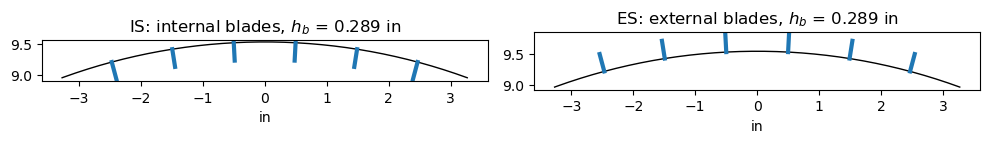

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
for ax, key, side in zip(axes, ('IS', 'ES'), ('internal', 'external')):
    t = TABLE_I[key]
    R = t['R']
    tb, hb = BLADE[key]
    th = np.linspace(np.pi/2 - 0.35, np.pi/2 + 0.35, 200)
    ax.plot(R*np.cos(th), R*np.sin(th), 'k-', lw=1)
    for k in range(-3, 3):
        thk = np.pi/2 + (k + 0.5)*2*np.pi/NSTIFF
        r2 = R - hb/IN if side == 'internal' else R + hb/IN
        ax.plot([R*np.cos(thk), r2*np.cos(thk)], [R*np.sin(thk), r2*np.sin(thk)], 'C0-', lw=3)
    ax.set_aspect('equal')
    ax.set_title('%s: %s blades, $h_b$ = %.3f in' % (key, side, hb/IN))
    ax.set_xlabel('in')
plt.tight_layout()
plt.show()

### Check of the half model

The simply supported IS shell, with a coarse number of terms, as a half and as a full cylinder: lowest frequency of each $(m, n)$ with $m \le 2$, $n \le 10$. In the full cylinder each $n$ appears twice ($\cos n\theta$ and $\sin n\theta$); the lower one is shown.

In [6]:
t = TABLE_I['IS']
tb, hb = BLADE['IS']
args = (t['R']*IN, t['h']*IN, LENGTH['SS']*IN, E, NU, RHO)
kw = dict(nstiff=NSTIFF, tb=tb, hb=hb, side='internal', bc='SS', mx=10, ny=6, nyb=4)
out = {}
for full in (False, True):
    md, skin, blades = bu.build_cylinder(*args, full=full, **kw)
    modes, dt, rres = bu.frequencies(md, skin, t['R']*IN, 'SS', num_eigvalues=80 if full else 40)
    out[full] = bu.lowest_by_mn(modes)
    print('%s cylinder: %d dofs before the connections, %.1f s, max. relative residual %.1e'
          % ('full' if full else 'half', md.get_size(), dt, rres))
rows = []
for mn in sorted(out[False]):
    if mn[0] <= 2 and 2 <= mn[1] <= 10 and mn in out[True]:
        rows.append(['%d, %d' % mn, '%.2f' % out[False][mn], '%.2f' % out[True][mn],
                     '%+.3f%%' % pct(out[False][mn], out[True][mn])])
display(markdown_table(['m, n', 'half, Hz', 'full, Hz', 'half vs full'], rows))

half cylinder: 9060 dofs before the connections, 6.7 s, max. relative residual 7.4e-08


full cylinder: 18000 dofs before the connections, 25.8 s, max. relative residual 1.5e-07


| m, n | half, Hz | full, Hz | half vs full |
|---|---|---|---|
| 1, 2 | 628.04 | 628.03 | +0.001% |
| 1, 3 | 368.75 | 368.75 | +0.000% |
| 1, 4 | 233.12 | 233.12 | +0.000% |
| 1, 5 | 165.01 | 165.01 | +0.000% |
| 1, 6 | 139.42 | 139.42 | +0.000% |
| 1, 7 | 142.02 | 142.02 | +0.000% |
| 1, 8 | 161.26 | 161.26 | +0.000% |
| 1, 9 | 189.85 | 189.85 | +0.000% |
| 1, 10 | 224.36 | 224.36 | +0.000% |
| 2, 4 | 652.68 | 652.68 | +0.001% |
| 2, 5 | 485.19 | 485.19 | +0.000% |
| 2, 6 | 383.97 | 383.97 | +0.000% |
| 2, 7 | 332.18 | 332.18 | +0.000% |
| 2, 8 | 316.53 | 316.53 | +0.000% |
| 2, 9 | 325.22 | 325.22 | +0.000% |
| 2, 10 | 349.12 | 349.12 | +0.000% |

## Convergence

The number of Ritz terms is increased in four steps, $m_x$ along $x$ (skin and blades, the same such that the connections along $x$ are exact), $n_y$ across a full skin bay and $n_b$ across a blade (at least 4, the minimum for which the base-flange connection does not lock, see `MultiDomain.check_conn_terms`). The table gives, for each shell and boundary condition, the largest relative change of the frequencies of all the measured $(m, n)$ from the previous step. The column residual is the largest relative residual of the eigenpairs, $\|(\boldsymbol{K} - \omega^2 \boldsymbol{M}) \boldsymbol{\phi}\| / \|\boldsymbol{K} \boldsymbol{\phi}\|$. The last step is used in the comparisons.

In [7]:
LEVELS = [(8, 4, 4), (10, 6, 4), (12, 8, 5), (14, 10, 6)]
NUM_EIGVALUES = 200
CASES = [(key, bc) for key in ('U', 'IS', 'ES') for bc in ('SS', 'FF', 'CC', 'CF')]
RES = {}
MODES = {}
rows = []
for key, bc in CASES:
    t = TABLE_I[key]
    R = t['R']*IN
    tb, hb = BLADE.get(key, (None, None))
    side = 'internal' if key == 'IS' else 'external'
    prev = None
    for i, (mx, ny, nyb) in enumerate(LEVELS):
        md, skin, blades = bu.build_cylinder(R, t['h']*IN, LENGTH[bc]*IN, E, NU, RHO,
                nstiff=NSTIFF, tb=tb, hb=hb, side=side, bc=bc, mx=mx, ny=ny, nyb=nyb)
        modes, dt, rres = bu.frequencies(md, skin, R, bc, num_eigvalues=NUM_EIGVALUES)
        low = bu.lowest_by_mn(modes)
        RES[(key, bc, i)] = low
        common = [mn for mn in TESTS[(key, bc)] if mn in low and prev is not None and mn in prev]
        change = max(abs(pct(low[mn], prev[mn])) for mn in common) if common else float('nan')
        rows.append([key, bc, '%d, %d, %d' % (mx, ny, nyb), md.get_size(), '%.0f' % modes[-1][0],
                     '%.1f' % dt, '%.0e' % rres, '-' if prev is None else '%.2f%%' % change])
        prev = low
    MODES[(key, bc)] = (md, skin, modes)
display(markdown_table(['shell', 'ends', 'm_x, n_y, n_b', 'dofs', 'highest f, Hz', 'time, s',
                        'residual', 'max. change'], rows))
FINAL = len(LEVELS) - 1

| shell | ends | m_x, n_y, n_b | dofs | highest f, Hz | time, s | residual | max. change |
|---|---|---|---|---|---|---|---|
| U | SS | 8, 4, 4 | 2976 | 3299 | 26.5 | 5e-07 | - |
| U | SS | 10, 6, 4 | 5460 | 2446 | 28.3 | 2e-06 | 0.58% |
| U | SS | 12, 8, 5 | 8640 | 2328 | 31.9 | 5e-07 | 0.00% |
| U | SS | 14, 10, 6 | 12600 | 2028 | 39.2 | 6e-06 | 0.00% |
| U | FF | 8, 4, 4 | 2976 | 2370 | 26.7 | 1e-05 | - |
| U | FF | 10, 6, 4 | 5460 | 2165 | 28.4 | 2e-05 | 0.55% |
| U | FF | 12, 8, 5 | 8640 | 1827 | 32.6 | 1e-04 | 0.12% |
| U | FF | 14, 10, 6 | 12600 | 1763 | 37.3 | 2e-04 | 0.09% |
| U | CC | 8, 4, 4 | 2976 | 7708 | 26.7 | 1e-08 | - |
| U | CC | 10, 6, 4 | 5460 | 3163 | 27.7 | 8e-08 | 1.37% |
| U | CC | 12, 8, 5 | 8640 | 2343 | 30.0 | 1e-07 | 0.75% |
| U | CC | 14, 10, 6 | 12600 | 2072 | 35.4 | 2e-07 | 0.36% |
| U | CF | 8, 4, 4 | 2976 | 3306 | 26.6 | 3e-07 | - |
| U | CF | 10, 6, 4 | 5460 | 2527 | 28.1 | 8e-07 | 0.64% |
| U | CF | 12, 8, 5 | 8640 | 2063 | 31.1 | 2e-06 | 0.33% |
| U | CF | 14, 10, 6 | 12600 | 1936 | 36.6 | 4e-06 | 0.16% |
| IS | SS | 8, 4, 4 | 5856 | 3525 | 27.3 | 4e-07 | - |
| IS | SS | 10, 6, 4 | 9060 | 2825 | 29.7 | 1e-06 | 1.24% |
| IS | SS | 12, 8, 5 | 14040 | 2733 | 34.9 | 7e-07 | 0.12% |
| IS | SS | 14, 10, 6 | 20160 | 2603 | 42.3 | 1e-06 | 0.12% |
| IS | FF | 8, 4, 4 | 5856 | 2556 | 27.6 | 2e-04 | - |
| IS | FF | 10, 6, 4 | 9060 | 2190 | 31.2 | 2e-04 | 0.35% |
| IS | FF | 12, 8, 5 | 14040 | 2067 | 36.4 | 4e-05 | 0.02% |
| IS | FF | 14, 10, 6 | 20160 | 2027 | 43.6 | 2e-05 | 0.03% |
| IS | CC | 8, 4, 4 | 5856 | 4347 | 26.8 | 9e-08 | - |
| IS | CC | 10, 6, 4 | 9060 | 3004 | 28.4 | 4e-07 | 3.42% |
| IS | CC | 12, 8, 5 | 14040 | 2918 | 32.3 | 3e-07 | 0.47% |
| IS | CC | 14, 10, 6 | 20160 | 2853 | 39.8 | 9e-08 | 0.18% |
| IS | CF | 8, 4, 4 | 5856 | 3306 | 27.5 | 3e-06 | - |
| IS | CF | 10, 6, 4 | 9060 | 2545 | 29.4 | 9e-06 | 0.56% |
| IS | CF | 12, 8, 5 | 14040 | 2376 | 34.5 | 6e-05 | 0.14% |
| IS | CF | 14, 10, 6 | 20160 | 2357 | 41.5 | 8e-07 | 0.09% |
| ES | SS | 8, 4, 4 | 5856 | 3484 | 27.5 | 2e-07 | - |
| ES | SS | 10, 6, 4 | 9060 | 2813 | 29.6 | 4e-07 | 0.46% |
| ES | SS | 12, 8, 5 | 14040 | 2710 | 34.5 | 4e-06 | 0.09% |
| ES | SS | 14, 10, 6 | 20160 | 2702 | 43.3 | 4e-07 | 0.09% |
| ES | FF | 8, 4, 4 | 5856 | 2466 | 27.6 | 2e-04 | - |
| ES | FF | 10, 6, 4 | 9060 | 2236 | 30.6 | 2e-04 | 0.38% |
| ES | FF | 12, 8, 5 | 14040 | 2168 | 36.5 | 2e-05 | 0.02% |
| ES | FF | 14, 10, 6 | 20160 | 2150 | 45.1 | 1e-04 | 0.03% |
| ES | CC | 8, 4, 4 | 5856 | 4302 | 26.8 | 7e-08 | - |
| ES | CC | 10, 6, 4 | 9060 | 3077 | 29.0 | 2e-07 | 0.78% |
| ES | CC | 12, 8, 5 | 14040 | 2917 | 32.3 | 2e-07 | 0.43% |
| ES | CC | 14, 10, 6 | 20160 | 2879 | 38.4 | 6e-08 | 0.28% |
| ES | CF | 8, 4, 4 | 5856 | 3340 | 27.7 | 7e-06 | - |
| ES | CF | 10, 6, 4 | 9060 | 2609 | 30.2 | 6e-06 | 0.55% |
| ES | CF | 12, 8, 5 | 14040 | 2493 | 35.0 | 3e-05 | 0.28% |
| ES | CF | 14, 10, 6 | 20160 | 2481 | 41.6 | 8e-06 | 0.18% |

## Comparison with the tests

For each boundary condition, the measured frequency (mean of a dual resonance, air shaker for FF) and the frequency of `panels` for the same $(m, n)$ (lowest mode classified with these wave numbers by `bu.classify`), with the relative difference.

In [8]:
SUMMARY = []
for bc, table in (('SS', 'II'), ('FF', 'III'), ('CC', 'IV'), ('CF', 'V')):
    keys = sorted(set(mn for key in ('U', 'IS', 'ES') for mn in TESTS[(key, bc)]))
    rows = []
    for mn in keys:
        row = ['%d, %d' % mn]
        for key in ('U', 'IS', 'ES'):
            test = TESTS[(key, bc)].get(mn)
            calc = RES[(key, bc, FINAL)].get(mn)
            if test is None:
                row += ['', '']
            elif calc is None:
                row += ['%.1f' % test[0], 'not found']
            else:
                row += ['%.1f' % test[0], '%.1f (%+.1f%%)' % (calc, pct(calc, test[0]))]
        rows.append(row)
    display(Markdown('**%s, Table %s of the report**' % (bc, table)))
    display(markdown_table(['m, n', 'U test, Hz', 'U panels', 'IS test, Hz', 'IS panels',
                            'ES test, Hz', 'ES panels'], rows))
    for key in ('U', 'IS', 'ES'):
        d = [pct(RES[(key, bc, FINAL)][mn], v[0]) for mn, v in TESTS[(key, bc)].items()
             if mn in RES[(key, bc, FINAL)]]
        SUMMARY.append([bc, key, len(d), '%+.1f%%' % np.mean(d), '%.1f%%' % np.mean(np.abs(d)),
                        '%+.1f%%' % min(d), '%+.1f%%' % max(d)])

**SS, Table II of the report**

| m, n | U test, Hz | U panels | IS test, Hz | IS panels | ES test, Hz | ES panels |
|---|---|---|---|---|---|---|
| 1, 4 | 287.0 | 287.5 (+0.2%) | 233.0 | 233.1 (+0.0%) |  |  |
| 1, 5 | 207.0 | 201.8 (-2.5%) | 175.0 | 164.9 (-5.8%) | 231.0 | 228.2 (-1.2%) |
| 1, 6 | 175.0 | 166.5 (-4.8%) | 142.0 | 139.2 (-2.0%) | 199.0 | 195.4 (-1.8%) |
| 1, 7 | 166.0 | 166.2 (+0.1%) | 146.0 | 141.7 (-2.9%) | 189.0 | 185.6 (-1.8%) |
| 1, 8 | 188.0 | 189.2 (+0.7%) | 169.0 | 160.9 (-4.8%) | 199.0 | 192.1 (-3.5%) |
| 1, 9 | 224.0 | 226.8 (+1.3%) | 203.0 | 189.5 (-6.7%) | 219.0 | 210.2 (-4.0%) |
| 1, 10 | 268.0 | 274.0 (+2.2%) | 243.0 | 224.0 (-7.8%) | 252.0 | 236.8 (-6.0%) |
| 1, 11 | 326.0 | 328.5 (+0.8%) | 290.0 | 263.0 (-9.3%) | 290.0 | 269.7 (-7.0%) |
| 1, 12 | 383.5 | 389.4 (+1.5%) | 333.0 | 306.0 (-8.1%) | 336.0 | 308.0 (-8.3%) |
| 1, 13 | 440.0 | 456.1 (+3.7%) | 392.0 | 352.6 (-10.0%) | 382.0 | 350.7 (-8.2%) |
| 1, 14 |  |  | 450.0 | 402.8 (-10.5%) | 440.0 | 397.5 (-9.7%) |
| 1, 15 | 590.0 | 606.3 (+2.8%) | 502.0 | 456.4 (-9.1%) | 500.0 | 448.0 (-10.4%) |
| 2, 8 | 345.5 | 345.0 (-0.1%) | 319.0 | 316.0 (-1.0%) |  |  |
| 2, 9 |  |  | 333.0 | 324.5 (-2.5%) |  |  |
| 2, 10 | 340.5 | 341.6 (+0.3%) | 366.0 | 348.3 (-4.8%) | 473.5 | 468.9 (-1.0%) |
| 2, 11 | 369.5 | 374.8 (+1.4%) | 399.0 | 381.6 (-4.4%) | 489.0 | 479.6 (-1.9%) |
| 2, 12 | 410.0 | 423.0 (+3.2%) | 443.0 | 421.1 (-4.9%) | 509.5 | 499.4 (-2.0%) |
| 2, 13 | 475.0 | 482.1 (+1.5%) | 482.0 | 465.4 (-3.4%) | 546.0 | 527.0 (-3.5%) |
| 2, 14 |  |  | 555.5 | 513.7 (-7.5%) | 590.0 | 561.2 (-4.9%) |
| 2, 15 |  |  |  |  | 630.0 | 601.2 (-4.6%) |
| 3, 8 |  |  | 603.5 | 581.9 (-3.6%) |  |  |
| 3, 11 | 499.0 | 496.1 (-0.6%) | 622.0 | 601.8 (-3.3%) |  |  |
| 3, 12 | 513.5 | 512.8 (-0.1%) | 664.0 | 635.4 (-4.3%) |  |  |
| 3, 14 | 604.0 | 602.8 (-0.2%) | 761.0 | 720.4 (-5.3%) |  |  |

**FF, Table III of the report**

| m, n | U test, Hz | U panels | IS test, Hz | IS panels | ES test, Hz | ES panels |
|---|---|---|---|---|---|---|
| 0, 2 | 7.2 | 7.2 (+0.2%) | 6.1 | 5.2 (-14.9%) | 5.9 | 5.0 (-15.4%) |
| 0, 3 | 20.1 | 20.4 (+1.5%) | 16.1 | 14.7 (-8.9%) | 15.7 | 14.1 (-10.0%) |
| 0, 4 | 37.9 | 39.1 (+3.2%) | 30.4 | 28.1 (-7.7%) | 30.6 | 27.1 (-11.4%) |
| 0, 5 | 61.9 | 63.3 (+2.2%) | 51.1 | 45.4 (-11.2%) | 50.1 | 43.8 (-12.6%) |
| 0, 6 | 91.6 | 92.8 (+1.3%) | 74.0 | 66.5 (-10.2%) | 71.0 | 64.2 (-9.5%) |
| 0, 7 | 125.0 | 127.8 (+2.2%) | 102.0 | 91.4 (-10.4%) | 98.0 | 88.3 (-9.9%) |
| 0, 8 | 165.0 | 168.1 (+1.9%) | 132.0 | 120.0 (-9.1%) | 129.0 | 116.0 (-10.1%) |
| 0, 9 | 210.0 | 213.7 (+1.8%) | 170.0 | 152.5 (-10.3%) | 165.0 | 147.4 (-10.7%) |
| 0, 10 | 262.0 | 264.8 (+1.1%) | 210.0 | 188.6 (-10.2%) | 208.0 | 182.3 (-12.4%) |
| 0, 11 | 318.0 | 321.2 (+1.0%) | 255.0 | 228.4 (-10.4%) | 249.0 | 220.7 (-11.4%) |
| 0, 12 | 378.0 | 383.0 (+1.3%) | 302.0 | 271.8 (-10.0%) | 295.0 | 262.6 (-11.0%) |
| 0, 13 | 443.0 | 450.1 (+1.6%) | 351.0 | 318.8 (-9.2%) | 348.0 | 308.0 (-11.5%) |
| 0, 14 | 512.0 | 522.6 (+2.1%) | 410.0 | 369.2 (-9.9%) | 403.0 | 356.7 (-11.5%) |
| 1, 2 | 9.2 | 8.7 (-5.1%) | 15.8 | 15.6 (-1.4%) | 15.2 | 15.6 (+2.6%) |
| 1, 3 | 22.3 | 22.7 (+1.7%) | 31.4 | 32.1 (+2.3%) | 31.1 | 32.2 (+3.4%) |
| 1, 4 | 40.3 | 41.7 (+3.5%) | 50.4 | 49.9 (-0.9%) | 49.4 | 49.9 (+0.9%) |
| 1, 5 | 65.0 | 66.0 (+1.5%) | 70.3 | 70.1 (-0.3%) | 69.7 | 69.7 (-0.0%) |
| 1, 6 | 94.6 | 95.6 (+1.0%) | 95.8 | 93.0 (-2.9%) | 94.0 | 92.2 (-1.9%) |
| 1, 7 | 129.0 | 130.5 (+1.2%) | 124.0 | 119.1 (-4.0%) | 122.0 | 117.7 (-3.5%) |
| 1, 8 | 170.0 | 170.8 (+0.5%) | 158.0 | 148.4 (-6.1%) | 159.0 | 146.4 (-7.9%) |
| 1, 9 | 214.0 | 216.4 (+1.1%) | 195.0 | 181.2 (-7.1%) | 189.0 | 178.4 (-5.6%) |
| 1, 10 | 266.0 | 267.4 (+0.5%) | 234.0 | 217.6 (-7.0%) | 232.0 | 213.7 (-7.9%) |
| 1, 11 | 322.0 | 323.8 (+0.6%) | 280.0 | 257.5 (-8.0%) | 273.0 | 252.3 (-7.6%) |
| 1, 12 | 382.0 | 385.5 (+0.9%) | 330.0 | 301.0 (-8.8%) | 318.0 | 294.3 (-7.5%) |
| 1, 13 | 452.0 | 452.6 (+0.1%) | 382.0 | 348.0 (-8.9%) |  |  |
| 1, 14 | 521.0 | 525.0 (+0.8%) |  |  | 430.0 | 388.1 (-9.7%) |
| 1, 15 |  |  |  |  | 493.0 | 440.0 (-10.8%) |
| 2, 5 | 367.0 | 394.7 (+7.5%) |  |  |  |  |
| 2, 6 | 292.0 | 296.9 (+1.7%) | 273.0 | 255.5 (-6.4%) |  |  |
| 2, 7 | 242.0 | 251.0 (+3.7%) | 245.0 | 235.3 (-4.0%) |  |  |
| 2, 8 | 235.0 | 242.5 (+3.2%) | 252.0 | 244.1 (-3.1%) | 320.0 | 328.5 (+2.7%) |
| 2, 9 | 252.0 | 260.9 (+3.5%) | 276.0 | 268.8 (-2.6%) | 330.0 | 333.6 (+1.1%) |
| 2, 10 | 290.0 | 297.4 (+2.5%) | 312.0 | 302.4 (-3.1%) | 352.0 | 350.8 (-0.3%) |
| 2, 11 | 339.0 | 346.0 (+2.1%) | 358.0 | 341.6 (-4.6%) | 388.0 | 377.1 (-2.8%) |
| 2, 12 |  |  | 405.0 | 385.0 (-4.9%) | 422.0 | 410.4 (-2.7%) |
| 2, 13 | 459.0 | 468.1 (+2.0%) | 455.0 | 431.9 (-5.1%) | 470.0 | 449.3 (-4.4%) |
| 2, 14 | 533.0 | 539.1 (+1.2%) |  |  |  |  |
| 3, 13 | 501.0 | 510.8 (+2.0%) |  |  |  |  |
| 3, 14 | 564.0 | 573.9 (+1.8%) |  |  |  |  |

**CC, Table IV of the report**

| m, n | U test, Hz | U panels | IS test, Hz | IS panels | ES test, Hz | ES panels |
|---|---|---|---|---|---|---|
| 1, 4 |  |  | 356.0 | 356.1 (+0.0%) |  |  |
| 1, 5 | 323.0 | 350.9 (+8.6%) | 275.0 | 269.9 (-1.9%) | 347.0 | 366.8 (+5.7%) |
| 1, 6 | 263.0 | 277.3 (+5.4%) | 228.0 | 221.2 (-3.0%) | 313.0 | 321.7 (+2.8%) |
| 1, 7 | 233.0 | 241.2 (+3.5%) | 207.0 | 201.8 (-2.5%) | 282.0 | 296.8 (+5.3%) |
| 1, 8 | 227.0 | 235.9 (+3.9%) | 212.0 | 205.0 (-3.3%) | 272.0 | 287.4 (+5.7%) |
| 1, 9 | 244.0 | 254.7 (+4.4%) | 231.0 | 223.5 (-3.2%) | 287.0 | 290.6 (+1.3%) |
| 1, 10 | 281.0 | 290.7 (+3.5%) | 262.0 | 252.1 (-3.8%) | 305.0 | 304.2 (-0.3%) |
| 1, 11 |  |  | 305.0 | 287.5 (-5.8%) | 333.0 | 326.5 (-2.0%) |
| 1, 12 | 386.0 | 396.1 (+2.6%) | 356.0 | 328.0 (-7.9%) | 370.0 | 356.1 (-3.7%) |
| 1, 13 | 453.0 | 460.6 (+1.7%) | 405.0 | 372.8 (-8.0%) |  |  |
| 1, 14 | 515.0 | 531.6 (+3.2%) | 457.0 | 421.5 (-7.8%) | 466.0 | 433.3 (-7.0%) |
| 1, 15 |  |  | 522.0 | 473.9 (-9.2%) | 525.0 | 479.4 (-8.7%) |
| 2, 7 | 479.0 | 501.7 (+4.7%) | 449.0 | 442.3 (-1.5%) |  |  |
| 2, 8 | 420.5 | 433.5 (+3.1%) | 423.0 | 418.1 (-1.2%) |  |  |
| 2, 9 |  |  | 418.0 | 417.2 (-0.2%) |  |  |
| 2, 10 |  |  | 435.0 | 432.8 (-0.5%) | 578.0 | 597.2 (+3.3%) |
| 2, 11 | 400.5 | 411.4 (+2.7%) | 467.0 | 459.5 (-1.6%) |  |  |
| 2, 12 |  |  |  |  | 605.0 | 616.0 (+1.8%) |
| 2, 13 | 490.0 | 500.1 (+2.1%) | 551.0 | 534.1 (-3.1%) | 630.0 | 636.9 (+1.1%) |
| 2, 14 | 552.0 | 562.8 (+1.9%) | 603.0 | 578.9 (-4.0%) |  |  |
| 2, 15 | 622.0 | 634.3 (+2.0%) | 660.0 | 627.5 (-4.9%) | 711.0 | 697.5 (-1.9%) |
| 3, 10 | 583.0 | 574.5 (-1.5%) |  |  |  |  |
| 3, 11 | 562.0 | 553.4 (-1.5%) |  |  |  |  |
| 3, 12 |  |  | 760.0 | 765.5 (+0.7%) |  |  |
| 3, 13 |  |  | 803.0 | 800.8 (-0.3%) |  |  |
| 3, 14 |  |  | 846.0 | 841.5 (-0.5%) |  |  |
| 3, 15 | 690.0 | 688.5 (-0.2%) |  |  |  |  |

**CF, Table V of the report**

| m, n | U test, Hz | U panels | IS test, Hz | IS panels | ES test, Hz | ES panels |
|---|---|---|---|---|---|---|
| 1, 2 |  |  |  |  | 277.0 | 284.6 (+2.7%) |
| 1, 3 | 156.0 | 168.4 (+7.9%) | 147.0 | 145.6 (-0.9%) | 163.5 | 168.2 (+2.8%) |
| 1, 4 | 107.0 | 108.0 (+1.0%) | 99.0 | 92.9 (-6.2%) | 112.0 | 115.7 (+3.3%) |
| 1, 5 | 90.0 | 92.3 (+2.6%) | 81.5 | 77.7 (-4.7%) | 95.5 | 96.4 (+0.9%) |
| 1, 6 | 102.0 | 104.8 (+2.8%) | 91.5 | 85.6 (-6.4%) | 100.0 | 97.8 (-2.2%) |
| 1, 7 | 130.0 | 133.3 (+2.6%) | 113.0 | 105.5 (-6.6%) | 121.0 | 112.4 (-7.1%) |
| 1, 8 | 166.0 | 171.1 (+3.1%) | 143.0 | 132.1 (-7.6%) | 147.0 | 135.3 (-8.0%) |
| 1, 9 | 208.0 | 215.7 (+3.7%) | 177.0 | 163.5 (-7.6%) | 181.0 | 163.9 (-9.5%) |
| 1, 10 | 260.0 | 266.3 (+2.4%) | 217.0 | 199.1 (-8.3%) | 219.5 | 197.1 (-10.2%) |
| 1, 11 | 317.0 | 322.4 (+1.7%) | 267.0 | 238.5 (-10.7%) | 259.0 | 234.3 (-9.5%) |
| 1, 12 | 374.0 | 384.0 (+2.7%) | 312.0 | 281.7 (-9.7%) | 316.0 | 275.4 (-12.8%) |
| 1, 13 |  |  | 363.0 | 328.5 (-9.5%) | 360.0 | 320.1 (-11.1%) |
| 1, 14 | 523.0 | 523.6 (+0.1%) | 425.0 | 378.8 (-10.9%) | 418.0 | 368.3 (-11.9%) |
| 1, 15 |  |  | 486.0 | 432.6 (-11.0%) | 495.0 | 419.9 (-15.2%) |
| 2, 4 |  |  | 390.0 | 388.3 (-0.4%) | 473.0 | 483.6 (+2.2%) |
| 2, 5 | 341.0 | 360.8 (+5.8%) | 303.0 | 286.5 (-5.4%) | 377.0 | 391.9 (+4.0%) |
| 2, 6 | 276.0 | 280.1 (+1.5%) | 247.0 | 234.2 (-5.2%) | 340.0 | 339.0 (-0.3%) |
| 2, 7 | 240.0 | 241.9 (+0.8%) | 225.0 | 217.7 (-3.2%) | 309.0 | 312.0 (+1.0%) |
| 2, 8 | 229.0 | 236.9 (+3.4%) | 233.0 | 225.6 (-3.2%) | 299.5 | 303.9 (+1.5%) |
| 2, 9 | 246.0 | 256.6 (+4.3%) | 257.0 | 248.2 (-3.4%) |  |  |
| 2, 10 | 281.0 | 293.5 (+4.4%) | 292.5 | 279.6 (-4.4%) | 329.0 | 326.9 (-0.6%) |
| 2, 11 | 337.0 | 342.1 (+1.5%) | 331.0 | 316.8 (-4.3%) | 365.0 | 352.3 (-3.5%) |
| 2, 12 | 394.5 | 399.6 (+1.3%) | 384.0 | 358.6 (-6.6%) |  |  |
| 2, 13 | 458.0 | 464.2 (+1.4%) | 438.0 | 404.3 (-7.7%) | 444.0 | 422.3 (-4.9%) |
| 2, 14 | 531.0 | 535.2 (+0.8%) | 494.0 | 453.6 (-8.2%) |  |  |
| 2, 15 | 603.0 | 612.1 (+1.5%) | 535.0 | 506.3 (-5.4%) | 544.0 | 512.0 (-5.9%) |
| 3, 6 |  |  | 544.0 | 515.6 (-5.2%) |  |  |
| 3, 9 | 400.0 | 405.1 (+1.3%) | 434.0 | 425.7 (-1.9%) |  |  |
| 3, 10 |  |  | 456.0 | 445.1 (-2.4%) |  |  |
| 3, 11 | 410.5 | 415.9 (+1.3%) | 491.0 | 475.7 (-3.1%) |  |  |
| 3, 12 |  |  | 524.0 | 513.6 (-2.0%) |  |  |
| 3, 13 | 476.0 | 505.3 (+6.1%) | 584.0 | 556.7 (-4.7%) |  |  |
| 3, 14 | 558.0 | 568.2 (+1.8%) | 627.0 | 603.8 (-3.7%) |  |  |
| 3, 15 | 633.0 | 639.9 (+1.1%) |  |  |  |  |

Summary of the relative differences, panels against test, over the measured $(m, n)$ of each case:

In [9]:
display(markdown_table(['ends', 'shell', 'values', 'mean', 'mean abs.', 'min.', 'max.'], SUMMARY))

| ends | shell | values | mean | mean abs. | min. | max. |
|---|---|---|---|---|---|---|
| SS | U | 19 | +0.6% | 1.5% | -4.8% | +3.7% |
| SS | IS | 23 | -5.3% | 5.3% | -10.5% | +0.0% |
| SS | ES | 17 | -4.7% | 4.7% | -10.4% | -1.0% |
| FF | U | 37 | +1.6% | 1.9% | -5.1% | +7.5% |
| FF | IS | 33 | -6.6% | 6.8% | -14.9% | +2.3% |
| FF | ES | 32 | -6.5% | 7.2% | -15.4% | +3.4% |
| CC | U | 18 | +2.8% | 3.1% | -1.5% | +8.6% |
| CC | IS | 23 | -3.2% | 3.2% | -9.2% | +0.7% |
| CC | ES | 14 | +0.2% | 3.6% | -8.7% | +5.7% |
| CF | U | 27 | +2.6% | 2.6% | +0.1% | +7.9% |
| CF | IS | 32 | -5.6% | 5.6% | -11.0% | -0.4% |
| CF | ES | 23 | -4.1% | 5.7% | -15.2% | +4.0% |

**Lowest frequencies.** The lowest measured frequency of each case against the lowest frequency of `panels` among the measured wave numbers, and the wave numbers of both. The report states that the minimum frequencies of the externally stiffened shell are in all cases significantly higher than those of the internally stiffened shell (Summary, p. 1).

In [10]:
rows = []
for bc in ('SS', 'FF', 'CC', 'CF'):
    for key in ('U', 'IS', 'ES'):
        test = TESTS[(key, bc)]
        mn_t = min(test, key=lambda mn: test[mn][0])
        calc = RES[(key, bc, FINAL)]
        mn_c = min((mn for mn in calc if mn[1] >= 2), key=lambda mn: calc[mn])
        rows.append([bc, key, '%.1f at (%d, %d)' % ((test[mn_t][0],) + mn_t),
                     '%.1f at (%d, %d)' % ((calc[mn_c],) + mn_c), '%+.1f%%' % pct(calc[mn_c], test[mn_t][0])])
display(markdown_table(['ends', 'shell', 'test, Hz at (m, n)', 'panels, Hz at (m, n)', 'difference'], rows))

| ends | shell | test, Hz at (m, n) | panels, Hz at (m, n) | difference |
|---|---|---|---|---|
| SS | U | 166.0 at (1, 7) | 166.2 at (1, 7) | +0.1% |
| SS | IS | 142.0 at (1, 6) | 139.2 at (1, 6) | -2.0% |
| SS | ES | 189.0 at (1, 7) | 185.6 at (1, 7) | -1.8% |
| FF | U | 7.2 at (0, 2) | 7.2 at (0, 2) | +0.2% |
| FF | IS | 6.1 at (0, 2) | 5.2 at (0, 2) | -14.9% |
| FF | ES | 5.9 at (0, 2) | 5.0 at (0, 2) | -15.4% |
| CC | U | 227.0 at (1, 8) | 235.9 at (1, 8) | +3.9% |
| CC | IS | 207.0 at (1, 7) | 201.8 at (1, 7) | -2.5% |
| CC | ES | 272.0 at (1, 8) | 287.4 at (1, 8) | +5.7% |
| CF | U | 90.0 at (1, 5) | 92.3 at (1, 5) | +2.6% |
| CF | IS | 81.5 at (1, 5) | 77.7 at (1, 5) | -4.7% |
| CF | ES | 95.5 at (1, 5) | 96.4 at (1, 5) | +0.9% |

## Comparison with the discrete-stringer analysis of Egle and Sewall (1968)

Egle and Sewall computed the frequencies of the ES shell with the Rayleigh-Ritz method and each of the 60 stringers as a discrete beam (Table 2, p. 523, with the properties of their Table 1, p. 522: $R = 9.537$ in, $a = 24.00$ in, $h = 0.0256$ in, those of the ES shell of Table I). Their shell is freely supported, $v = w = 0$ with the axial displacement free at both ends, and the in-surface inertia is neglected (p. 522), which raises the frequencies at low $n$. Their values for $n = 4$ to 15 are compared with the SS model of the ES shell. (Two entries of their Table 2 are misprinted and not used here: $m = 1$, $n = 3$, "44.53", and the smeared value at $m = 1$, $n = 12$.)

In [11]:
# Egle and Sewall (1968), Table 2 (p. 523), 'Discrete' columns, cps, n = 4 to 15
EGLE_TABLE_2 = {
    1: [304.0, 231.8, 197.7, 188.2, 196.0, 216.1, 245.2, 281.2, 322.8, 369.3, 420.2, 475.2],
    2: [824.1, 674.8, 579.6, 520.3, 486.2, 471.1, 470.8, 482.5, 504.2, 534.5, 572.1, 616.2],
    3: [1291., 1132., 1022., 945.5, 894.7, 862.9, 846.1, 841.4, 846.9, 861.3, 883.6, 913.2],
}
calc = RES[('ES', 'SS', FINAL)]
rows = []
for n in range(4, 16):
    row = ['%d' % n]
    for m in (1, 2, 3):
        ref = EGLE_TABLE_2[m][n - 4]
        row += ['%.1f' % ref, '%.1f (%+.1f%%)' % (calc[(m, n)], pct(calc[(m, n)], ref))
                if (m, n) in calc else 'not found']
    rows.append(row)
display(markdown_table(['n', 'm=1 Egle', 'm=1 panels', 'm=2 Egle', 'm=2 panels',
                        'm=3 Egle', 'm=3 panels'], rows))

| n | m=1 Egle | m=1 panels | m=2 Egle | m=2 panels | m=3 Egle | m=3 panels |
|---|---|---|---|---|---|---|
| 4 | 304.0 | 296.2 (-2.6%) | 824.1 | 805.1 (-2.3%) | 1291.0 | 1266.1 (-1.9%) |
| 5 | 231.8 | 228.2 (-1.5%) | 674.8 | 664.7 (-1.5%) | 1132.0 | 1115.3 (-1.5%) |
| 6 | 197.7 | 195.4 (-1.2%) | 579.6 | 573.9 (-1.0%) | 1022.0 | 1008.7 (-1.3%) |
| 7 | 188.2 | 185.6 (-1.4%) | 520.3 | 516.9 (-0.6%) | 945.5 | 934.7 (-1.1%) |
| 8 | 196.0 | 192.1 (-2.0%) | 486.2 | 484.2 (-0.4%) | 894.7 | 885.1 (-1.1%) |
| 9 | 216.1 | 210.2 (-2.7%) | 471.1 | 469.5 (-0.3%) | 862.9 | 853.9 (-1.0%) |
| 10 | 245.2 | 236.8 (-3.4%) | 470.8 | 468.9 (-0.4%) | 846.1 | 837.2 (-1.1%) |
| 11 | 281.2 | 269.7 (-4.1%) | 482.5 | 479.6 (-0.6%) | 841.4 | 832.1 (-1.1%) |
| 12 | 322.8 | 308.0 (-4.6%) | 504.2 | 499.4 (-0.9%) | 846.9 | 836.7 (-1.2%) |
| 13 | 369.3 | 350.7 (-5.0%) | 534.5 | 527.0 (-1.4%) | 861.3 | 849.5 (-1.4%) |
| 14 | 420.2 | 397.5 (-5.4%) | 572.1 | 561.2 (-1.9%) | 883.6 | 869.5 (-1.6%) |
| 15 | 475.2 | 448.0 (-5.7%) | 616.2 | 601.2 (-2.4%) | 913.2 | 895.8 (-1.9%) |

## Frequency spectra

Frequencies against the circumferential wave number $n$: lines `panels` ($m$ = 0 to 3), markers the tests (mean of the dual resonances; air shaker for FF).

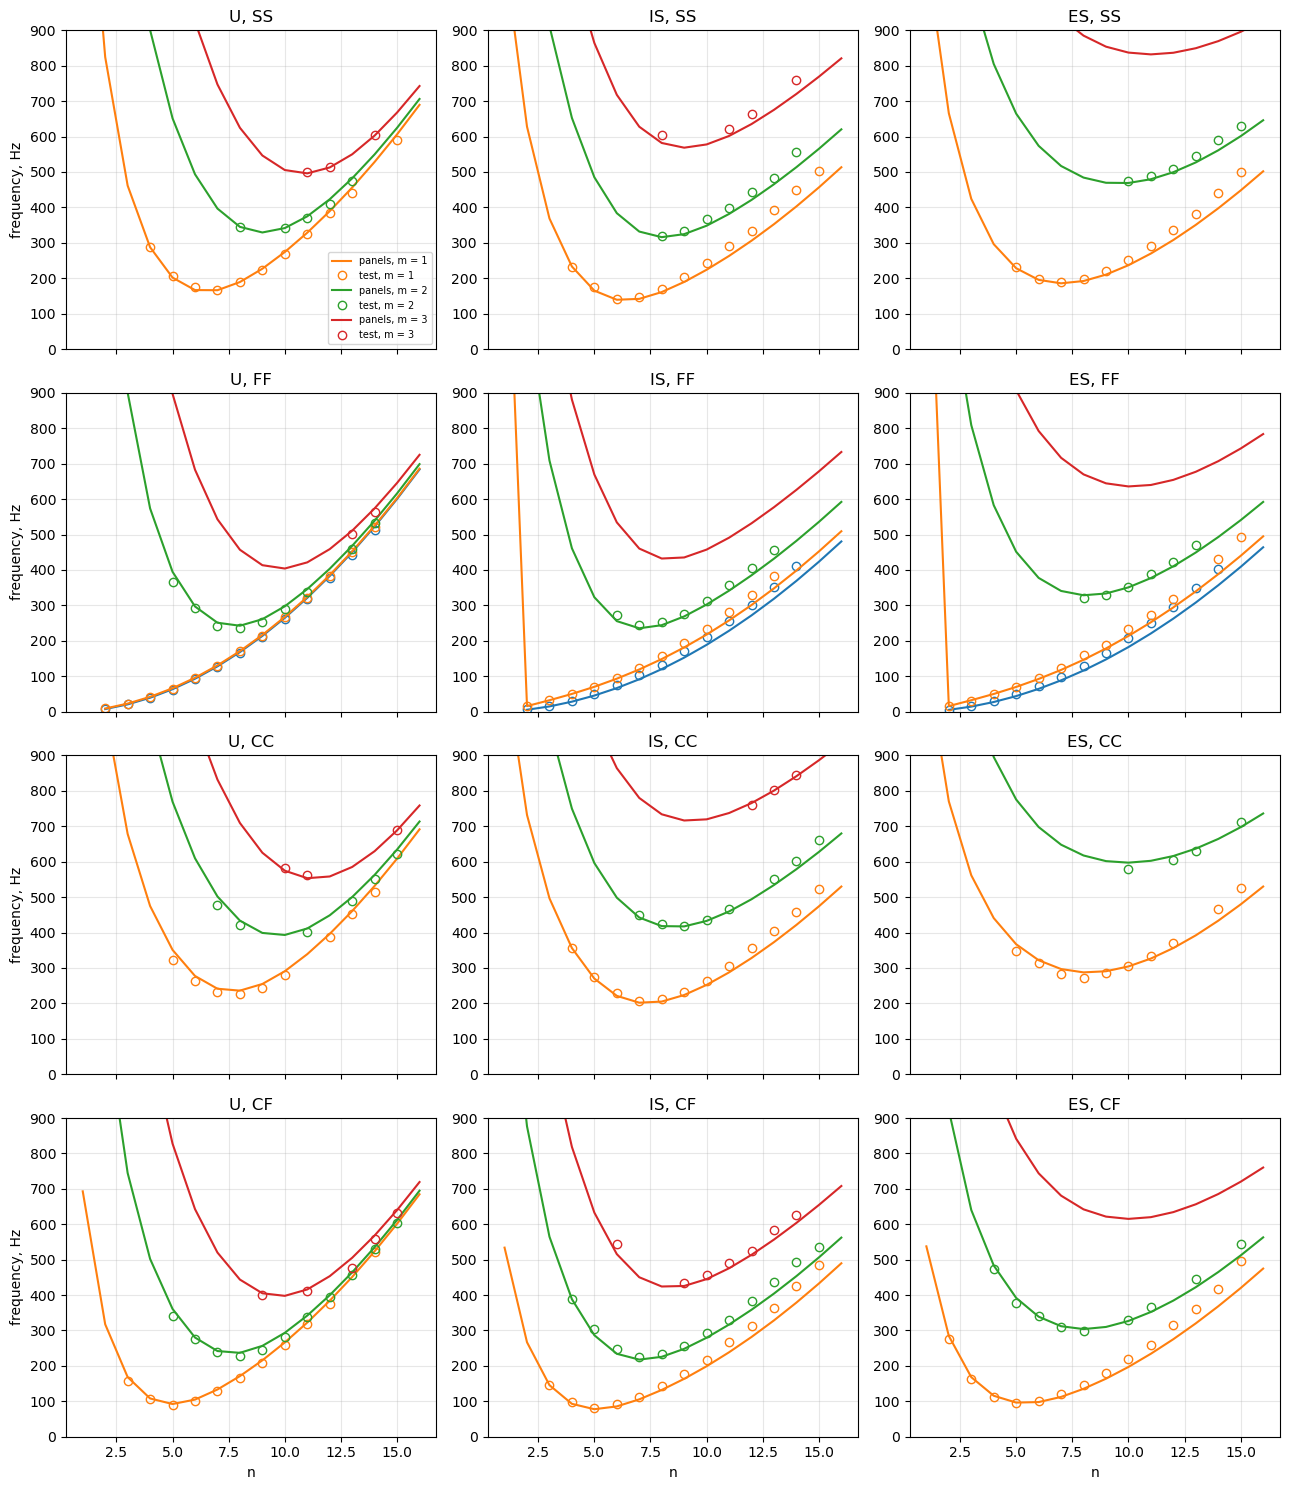

In [12]:
fig, axes = plt.subplots(4, 3, figsize=(13, 15), sharex=True)
for i, bc in enumerate(('SS', 'FF', 'CC', 'CF')):
    for j, key in enumerate(('U', 'IS', 'ES')):
        ax = axes[i, j]
        calc = RES[(key, bc, FINAL)]
        for m in range(0, 4):
            ns = sorted(n for (mm, n) in calc if mm == m and 1 <= n <= 16)
            if not ns:
                continue
            ax.plot(ns, [calc[(m, n)] for n in ns], '-', color='C%d' % m, label='panels, m = %d' % m)
            pts = [(n, v[0]) for (mm, n), v in TESTS[(key, bc)].items() if mm == m]
            if pts:
                ax.plot(*zip(*pts), 'o', mfc='none', color='C%d' % m, label='test, m = %d' % m)
        ax.set_ylim(0, 900)
        ax.set_title('%s, %s' % (key, bc))
        ax.grid(alpha=0.3)
        if j == 0:
            ax.set_ylabel('frequency, Hz')
        if i == 3:
            ax.set_xlabel('n')
axes[0, 0].legend(fontsize=7)
plt.tight_layout()
plt.show()

## Mode shapes

Normal displacement $w$ of the skin of the half cylinder, unrolled, for the mode of lowest frequency of the stiffened shells (excluding $n < 2$), $x$ along the axis and $\theta$ around the circumference; the dots mark the stringers.

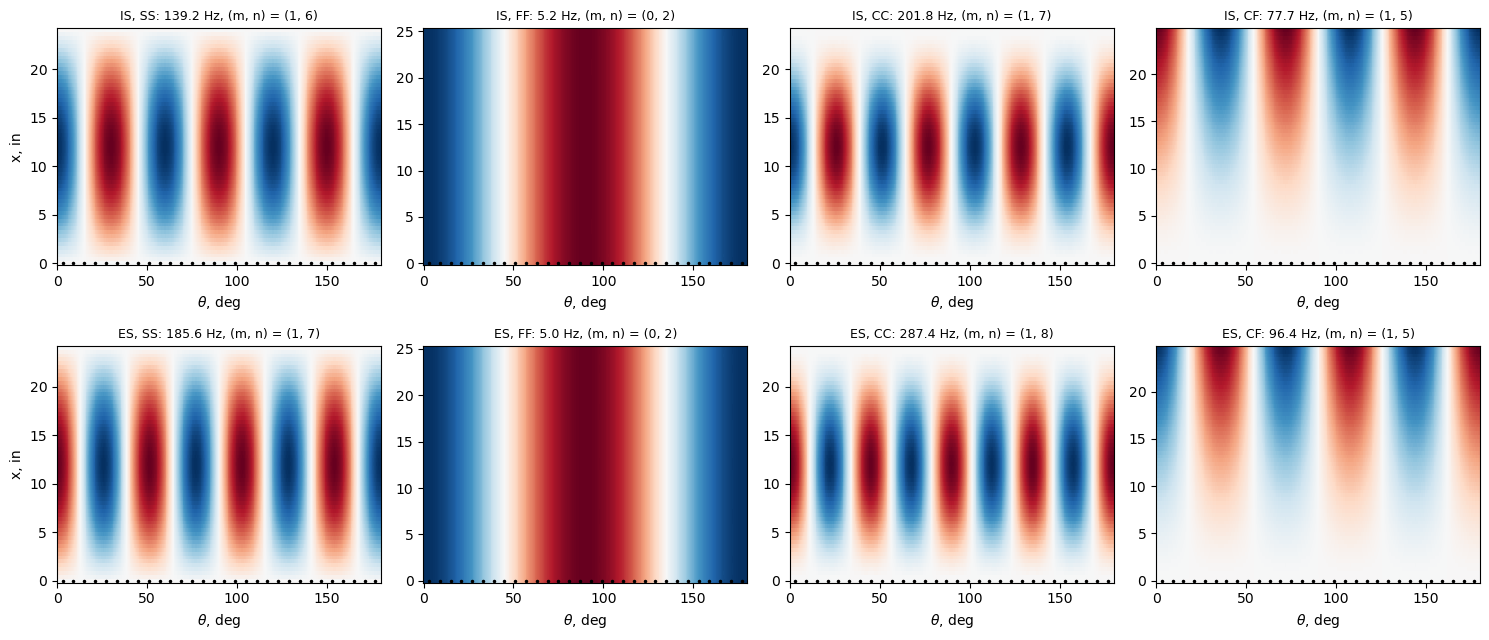

In [13]:
fig, axes = plt.subplots(2, 4, figsize=(15, 6.5))
for i, key in enumerate(('IS', 'ES')):
    t = TABLE_I[key]
    R = t['R']*IN
    for j, bc in enumerate(('SS', 'FF', 'CC', 'CF')):
        md, skin, modes = MODES[(key, bc)]
        f, m, n, c = next(mode for mode in modes if mode[2] >= 2)
        x, th, w = bu.skin_w(md, c, skin, R)
        ax = axes[i, j]
        ax.pcolormesh(np.degrees(th), x/IN, (w/np.abs(w).max()).T, cmap='RdBu_r', shading='auto', vmin=-1, vmax=1)
        ax.plot(np.degrees((np.arange(NSTIFF//2) + 0.5)*2*np.pi/NSTIFF), np.zeros(NSTIFF//2), 'k.', ms=3)
        ax.set_title('%s, %s: %.1f Hz, (m, n) = (%d, %d)' % (key, bc, f, m, n), fontsize=9)
        ax.set_xlabel(r'$\theta$, deg')
        if j == 0:
            ax.set_ylabel('x, in')
plt.tight_layout()
plt.show()

## Discussion

- **Convergence and symmetry.** In the last step of the convergence study the frequencies of the measured $(m, n)$ change by at most 0.4 %, and the half cylinder reproduces the frequencies of the full cylinder to within 0.001 %.
- **Unstiffened shell.** `panels` agrees with the tests to 1.5 % to 3.1 % on average (mean absolute difference) for the four boundary conditions, with no free parameter: the test procedures and the boundary conditions, which the unstiffened model was meant to evaluate (p. 6), are well represented. The clamped values are 2.6 % to 2.8 % above the tests on average, the largest differences (up to 8.6 %) at the lowest $n$ of CC and CF, where the potting in a low-melting-point alloy (p. 7) is a less rigid clamp than $u = v = w = w_{,x} = 0$.
- **Stiffened shells, low $n$.** For the modes with few circumferential waves, where the stringers act mainly through their axial bending stiffness and eccentricity, `panels` is within 6.5 % of the tests for $n \le 6$ with SS, CC and CF, e.g. the lowest frequencies of SS, $(m, n) = (1, 6)$ for IS and $(1, 7)$ for ES, 2.0 % and 1.8 % below the tests. The difference between external and internal stringers is reproduced: the lowest frequency of ES is 1.33 (SS), 1.42 (CC) and 1.24 (CF) times that of IS in `panels`, against 1.33, 1.31 and 1.17 in the tests. Free-free, the lowest modes $m = 0$ (inextensional) have almost the same frequency for IS and ES, in the tests and in `panels`.
- **Stiffened shells, high $n$.** The frequencies of `panels` fall increasingly below the tests as $n$ grows, to $-9$ % to $-15$ % at $n = 15$ for $m = 1$, for both IS and ES and all boundary conditions, and for the free-free modes $m = 0$ at all $n$. These modes are governed by the circumferential bending of the skin. In the test shells the skin under each stringer is 0.100 in wide and 0.28 in high, a tenth of the bay stiffened in circumferential bending; in the model the stringer is attached along a line and the skin keeps its thickness up to the stringer. Sewall and Naumann call this the local transverse bending stiffness due to the stiffeners, $D_y/D \ge 1$, which "significantly improved" the agreement of their analysis with the tests (Summary, p. 1); Egle and Sewall used $D_y/D = 1.197$ for the ES shell (Table 1). A circumferential bending stiffness 20 % higher raises a bending-dominated frequency by up to $\sqrt{1.197} - 1 = 9$ % (derived), the size of the differences at high $n$. The fillets, which the plate strips do not represent, add to this local stiffening.
- **Discrete-stringer analysis.** The frequencies of Egle and Sewall are 0.3 % to 2.4 % above `panels` for $m = 2$ and 3, and 1.2 % to 5.7 % above for $m = 1$, the difference growing with $n$ as against the tests. Their analysis includes $D_y/D = 1.197$ and neglects the in-surface inertia, which raises its frequencies at low $n$ (p. 522); `panels` includes the inertia of all displacements of the skin and of the blades.
- **Other differences.** The two welded longitudinal seams, where the skin tapers to 0.035 in at the butt (Fig. 1), are not modelled, nor the mass of the shaker attachment. The dual resonances, two frequencies for the same $(m, n)$, show that the test shells were not perfectly axisymmetric (p. 11); the model, symmetric by construction, gives one frequency per $(m, n)$, compared with the mean of the pair. The electrodynamic and the air shaker give frequencies of the lowest free-free modes that differ by up to 64 % ($n = 2$, Table III), the measure of the uncertainty of these modes; the air-shaker values are used.
- **Analytical results of the report.** The Rayleigh-Ritz frequencies of Sewall and Naumann (smeared stringers) are only plotted (e.g. Figs. 9 and 11) and are not compared here.